# Storyboard → ControlNet baseline pipeline

Step 1 of the project: a shared input pipeline that turns storyboard panels into layout-conditioning maps and generates one frame per panel with ControlNet.

**Before running:** Runtime → Change runtime type → **T4 GPU**.

Sections:
1. Setup and config
2. Panel cropping helpers
3. Conditioning map extraction
4. Load ControlNet
5. Sequence generation loop (saves outputs + config)
6. Side-by-side preview
7. Character reference crops
8. Hooks for the other methods

*Note: this notebook has not been run end to end. Model repo names on Hugging Face change occasionally, so if a download fails, check the current name.*

In [1]:
!pip install -q diffusers transformers accelerate opencv-python pymupdf
!pip install -U torchao


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 15.2 MB/s  0:00:00
  Attempting uninstall: torchao
    Found existing installation: torchao 0.10.0
    Uninstalling torchao-0.10.0:
      Successfully uninstalled torchao-0.10.0


## 1. Setup and config
Add the shared storyboard folder as a shortcut in My Drive (Drive → right-click folder → Organize → Add shortcut), then set the paths below.

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import os, json, glob, time
import numpy as np
import cv2
import torch
from PIL import Image
import matplotlib.pyplot as plt

# ---- EDIT THESE ----
PDF_PATH       = '/content/drive/MyDrive/cmpe261_project/storyboard/Evicted-Storyboard.pdf'   # the source PDF
STORYBOARD_DIR = '/content/drive/MyDrive/cmpe261_project/pages'                       # PDF pages rendered to PNG
PANEL_DIR      = '/content/drive/MyDrive/cmpe261_project/panels'         # cropped panels land here
OUTPUT_DIR     = '/content/drive/MyDrive/cmpe261_project/outputs'        # generated frames land here
REF_DIR        = '/content/drive/MyDrive/cmpe261_project/char_refs'      # character reference crops
for d in (STORYBOARD_DIR, PANEL_DIR, OUTPUT_DIR, REF_DIR):
    os.makedirs(d, exist_ok=True)

# One config used for every method so the comparison stays fair
CONFIG = {
    "base_model": "stable-diffusion-v1-5/stable-diffusion-v1-5",
    "controlnet": "lllyasviel/control_v11p_sd15_canny",
    "resolution": 512,
    "steps": 30,
    "guidance_scale": 7.5,
    "controlnet_conditioning_scale": 1.0,
    "seed": 42,
    "cond_mode": "canny",            # "canny" or "invert"
    "canny_low": 100,
    "canny_high": 200,
    "prompt_suffix": "clean colored animation frame, consistent character design",
    "negative_prompt": "blurry, low quality, deformed, extra limbs, text, watermark",
}
print('PDF exists:', os.path.exists(PDF_PATH))

PDF exists: False


### Render the PDF pages to images
The source storyboard is a PDF, so render each page to a PNG first. 200 DPI is a good starting point (higher keeps more line detail but makes files larger). Set `FIRST_PAGE`/`LAST_PAGE` (1-indexed) if the PDF holds more than you need.

In [6]:
import pymupdf  # PyMuPDF

DPI = 200
FIRST_PAGE, LAST_PAGE = 9, 11   # None = through the last page

doc = pymupdf.open(PDF_PATH)
print('pages in PDF:', len(doc))
last = LAST_PAGE or len(doc)
zoom = DPI / 72
for pno in range(FIRST_PAGE - 1, last):
    pix = doc[pno].get_pixmap(matrix=pymupdf.Matrix(zoom, zoom), alpha=False)
    pix.save(os.path.join(STORYBOARD_DIR, f'page{pno+1:03d}.png'))
print('saved pages to', STORYBOARD_DIR)

pages in PDF: 303
saved pages to /content/drive/MyDrive/cmpe261_project/pages


*Optional:* if the PDF pages are scans or embedded images, you can pull the embedded images at their original resolution instead of re-rendering, using `doc[pno].get_images()` and `doc.extract_image(xref)`. Rendering is simpler and works for any PDF, so start there.

## 2. Panel cropping helpers
Storyboard pages often hold several panels. Use whichever approach fits your files. Crop first, resize later.

In [7]:
def load_rgb(path):
    return Image.open(path).convert('RGB')   # drops alpha channels that break things downstream

def split_grid(img, rows, cols, margin=0):
    """Evenly split a page into rows x cols panels (reading order)."""
    w, h = img.size
    pw, ph = w // cols, h // rows
    panels = []
    for r in range(rows):
        for c in range(cols):
            box = (c*pw + margin, r*ph + margin, (c+1)*pw - margin, (r+1)*ph - margin)
            panels.append(img.crop(box))
    return panels

def detect_panels(img, min_w=150, min_h=100, thresh_val=200, row_tol=50):
    """Rough auto-detection via contours. Works only if panels have visible borders.
    Always check the result visually."""
    gray = cv2.cvtColor(np.array(img), cv2.COLOR_RGB2GRAY)
    _, thresh = cv2.threshold(gray, thresh_val, 255, cv2.THRESH_BINARY_INV)
    contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    boxes = []
    for c in contours:
        x, y, w, h = cv2.boundingRect(c)
        if w > min_w and h > min_h:
            boxes.append((x, y, x+w, y+h))
    boxes.sort(key=lambda b: (b[1] // row_tol, b[0]))
    return [img.crop(b) for b in boxes], boxes

def show(images, titles=None, cols=4, size=4):
    rows = (len(images) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(cols*size, rows*size))
    axes = np.array(axes).reshape(-1)
    for ax in axes: ax.axis('off')
    for i, im in enumerate(images):
        axes[i].imshow(im)
        if titles: axes[i].set_title(titles[i], fontsize=9)
    plt.tight_layout(); plt.show()

def save_sequence(panel_images, seq_name):
    paths = []
    for i, p in enumerate(panel_images, 1):
        path = os.path.join(PANEL_DIR, f'{seq_name}_panel{i:03d}.png')
        p.save(path); paths.append(path)
    return paths

3 files found
page size (w, h): (2800, 1700)
6 relevant panels


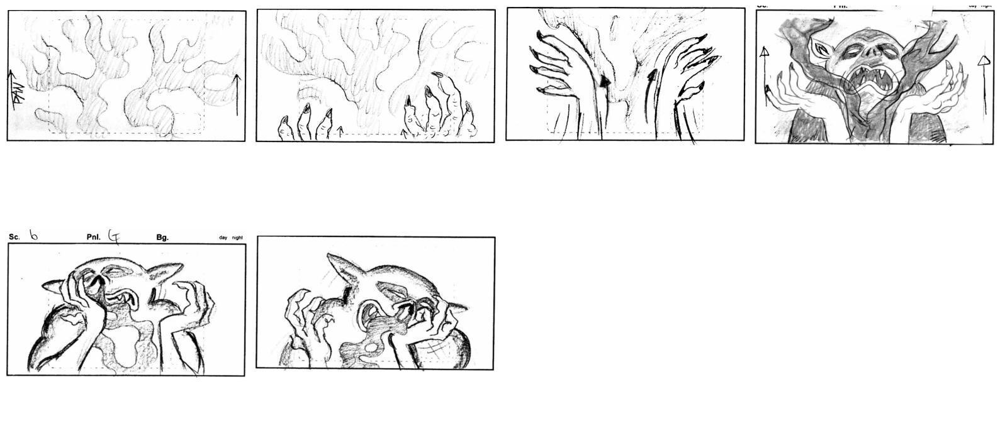

['/content/drive/MyDrive/cmpe261_project/panels/seq01_panel001.png',
 '/content/drive/MyDrive/cmpe261_project/panels/seq01_panel002.png',
 '/content/drive/MyDrive/cmpe261_project/panels/seq01_panel003.png',
 '/content/drive/MyDrive/cmpe261_project/panels/seq01_panel004.png',
 '/content/drive/MyDrive/cmpe261_project/panels/seq01_panel005.png',
 '/content/drive/MyDrive/cmpe261_project/panels/seq01_panel006.png']

In [8]:
# --- Example: inspect one page and crop it. Edit to match your files. ---
page_paths = sorted(glob.glob(os.path.join(STORYBOARD_DIR, '*.png')) +
                    glob.glob(os.path.join(STORYBOARD_DIR, '*.jpg')))
print(len(page_paths), 'files found')

page = load_rgb(page_paths[0])
print('page size (w, h):', page.size)

# Option A: grid split
# panels = split_grid(page, rows=3, cols=2, margin=10)
# Option B: auto-detect
# panels, boxes = detect_panels(page)
# Option C: manual boxes (left, upper, right, lower)
# panels = [page.crop((100, 50, 700, 450)), page.crop((720, 50, 1320, 450))]

# show(panels)
#save_panels(panels, 'seq01')

KEEP = slice(1, 3)   # the two middle panels of the four detected

all_panels = []      # (page_number, panel_image) in reading order
for pno, pp in enumerate(page_paths, 1):
    page = load_rgb(pp)
    panels, boxes = detect_panels(page)
    if len(panels) != 4:
        print(f'page {pno}: detected {len(panels)} panels, check this one manually')
        continue
    for p in panels[KEEP]:
        all_panels.append((pno, p))

print(len(all_panels), 'relevant panels')
show([p for _, p in all_panels[:8]], cols=4)


# e.g. pages 1-3 form one scene
scene_panels = [p for pno, p in all_panels if 1 <= pno <= 3]
save_sequence(scene_panels, 'seq01')

## 3. Conditioning map extraction
ControlNet's canny model expects **white lines on black**. Storyboards are usually dark lines on white, so try both modes and compare.

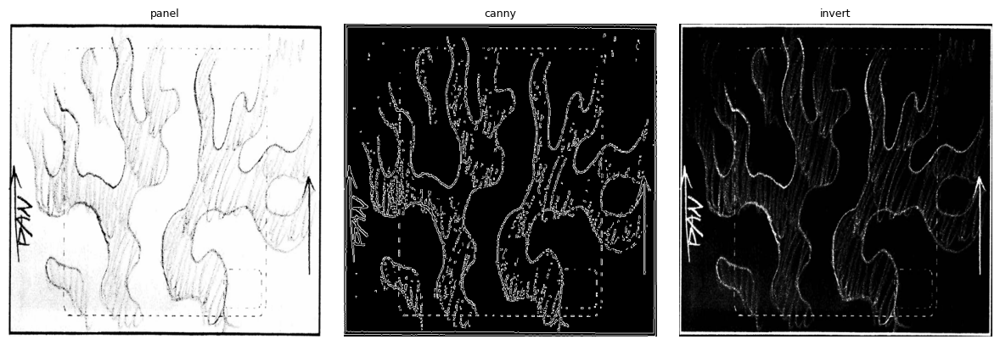

In [9]:
def make_condition(img, mode='canny', size=512, low=100, high=200):
    img = img.resize((size, size))   # same resize for every panel and every method
    gray = np.array(img.convert('L'))
    if mode == 'canny':
        cond = cv2.Canny(gray, low, high)
    elif mode == 'invert':
        cond = 255 - gray            # dark lines on white -> white lines on black
    else:
        raise ValueError(mode)
    return Image.fromarray(cond).convert('RGB')

# Quick comparison on one panel (run after you've saved some panels)
panel_paths = sorted(glob.glob(os.path.join(PANEL_DIR, '*.png')))
if panel_paths:
    test = load_rgb(panel_paths[0])
    show([test.resize((512, 512)),
          make_condition(test, 'canny'),
          make_condition(test, 'invert')],
         titles=['panel', 'canny', 'invert'], cols=3)

## Character crop one charcter to test piplne

In [10]:
from pathlib import Path
from typing import Protocol, TypeAlias

from PIL import Image

from transformers import (
    AutoProcessor,
    Florence2ForConditionalGeneration,
)

from transformers import Sam2Model, Sam2Processor

BBox: TypeAlias = tuple[int, int, int, int]

In [24]:
import gc

In [11]:
class CharacterLocator(Protocol):
    """Locates a requested character within an image."""

    def locate(
        self,
        image: Image.Image,
        prompt: str,
    ) -> BBox:
        """
        Locate a character and return its bounding box.

        Args:
            image: Source image.
            prompt: Character description such as "the vampire".

        Returns:
            Bounding box as (left, top, right, bottom).
        """
        ...

class CharacterSegmenter(Protocol):
    """Segments a character using a supplied bounding box."""

    def segment(
        self,
        image: Image.Image,
        bbox: BBox,
    ) -> Image.Image:
        """
        Produce a binary mask for the character inside `bbox`.

        Args:
            image: Source image.
            bbox: Character bounding box.

        Returns:
            Grayscale PIL mask where white represents the character
            and black represents the background.
        """
        ...

class BackgroundStrategy(Protocol):
    """Defines how the segmented character background is handled."""

    def apply(
        self,
        image: Image.Image,
        mask: Image.Image,
    ) -> Image.Image:
        """Apply background handling using the segmentation mask."""
        ...

In [12]:
class SolidBackgroundStrategy:
    """Replace the background with a solid color."""

    def __init__(
        self,
        color: str | tuple[int, int, int] = "white",
    ) -> None:
        self.color = color

    def apply(
        self,
        image: Image.Image,
        mask: Image.Image,
    ) -> Image.Image:
        image = image.convert("RGB")

        background = Image.new(
            mode="RGB",
            size=image.size,
            color=self.color,
        )

        return Image.composite(
            image,
            background,
            mask,
        )

def pad_bbox(
    bbox: BBox,
    image_size: tuple[int, int],
    padding: int = 10,
) -> BBox:
    """
    Add padding around a bounding box without exceeding image bounds.

    Args:
        bbox: Bounding box as (left, top, right, bottom).
        image_size: Image size as (width, height).
        padding: Pixels added to each side.

    Returns:
        Padded bounding box.
    """
    left, top, right, bottom = bbox
    width, height = image_size

    return (
        max(0, left - padding),
        max(0, top - padding),
        min(width, right + padding),
        min(height, bottom + padding),
    )

In [13]:
class Florence2CharacterLocator:
    """
    Uses Florence-2 caption-to-phrase grounding to locate a character.

    Given an image and phrase such as "the vampire", returns a bounding
    box in (left, top, right, bottom) format.
    """

    TASK_PROMPT = "<CAPTION_TO_PHRASE_GROUNDING>"

    def __init__(
        self,
        model_name: str = "florence-community/Florence-2-base",
        device: str | None = None,
    ) -> None:
        """
        Load Florence-2 using the native Transformers implementation.

        Args:
            model_name: Hugging Face Florence-2 checkpoint.
            device: Torch device. Automatically selects CUDA when available.
        """
        self.device = device or (
            "cuda" if torch.cuda.is_available() else "cpu"
        )

        self.dtype = (
            torch.float16
            if self.device == "cuda"
            else torch.float32
        )

        self.processor = AutoProcessor.from_pretrained(model_name)

        self.model = (
            Florence2ForConditionalGeneration
            .from_pretrained(
                model_name,
                dtype=self.dtype,
            )
            .to(self.device)
        )

        self.model.eval()

    @staticmethod
    def _bbox_area(bbox: BBox) -> int:
        """Return the area of a bounding box."""
        left, top, right, bottom = bbox

        return max(0, right - left) * max(0, bottom - top)

    def _select_bbox(
        self,
        parsed_output: dict,
    ) -> BBox:
        """
        Select a bounding box from Florence-2 output.

        For now, if multiple boxes are returned, choose the largest.
        """
        task_result = parsed_output.get(self.TASK_PROMPT)

        if task_result is None:
            raise ValueError(
                f"Florence-2 did not return results for "
                f"{self.TASK_PROMPT}.\n"
                f"Output: {parsed_output}"
            )

        bboxes = task_result.get("bboxes", [])

        if not bboxes:
            raise ValueError(
                "Florence-2 did not detect a matching character."
            )

        bboxes = [
            tuple(map(int, bbox))
            for bbox in bboxes
        ]

        return max(bboxes, key=self._bbox_area)

    def locate(
        self,
        image: Image.Image,
        prompt: str,
    ) -> BBox:
        """
        Locate a character described by `prompt`.

        Args:
            image: Source image.
            prompt: Character description, e.g. "the vampire".

        Returns:
            Bounding box as (left, top, right, bottom).
        """
        image = image.convert("RGB")

        # Florence phrase grounding expects:
        #
        # <CAPTION_TO_PHRASE_GROUNDING>the vampire
        #
        model_prompt = self.TASK_PROMPT + prompt

        inputs = self.processor(
            text=model_prompt,
            images=image,
            return_tensors="pt",
        )

        # Move tensors to the same device as the model.
        inputs = {
            key: (
                value.to(self.device, dtype=self.dtype)
                if value.is_floating_point()
                else value.to(self.device)
            )
            for key, value in inputs.items()
        }

        with torch.inference_mode():
            generated_ids = self.model.generate(
                **inputs,
                max_new_tokens=256,
                num_beams=3,
                do_sample=False,
            )

        generated_text = self.processor.batch_decode(
            generated_ids,
            skip_special_tokens=False,
        )[0]

        parsed_output = self.processor.post_process_generation(
            generated_text,
            task=self.TASK_PROMPT,
            image_size=image.size,
        )

        return self._select_bbox(parsed_output)

In [14]:
class SAM2CharacterSegmenter:
    """
    Segments a character using SAM 2.1 and a bounding-box prompt.

    The bounding box is expected to come from a CharacterLocator,
    such as Florence2CharacterLocator.
    """

    def __init__(
        self,
        model_name: str = "facebook/sam2.1-hiera-tiny",
        device: str | None = None,
    ) -> None:
        """
        Load SAM 2.1 Tiny.

        Args:
            model_name: Hugging Face SAM 2 checkpoint.
            device: Torch device. Automatically uses CUDA when available.
        """
        self.device = device or (
            "cuda" if torch.cuda.is_available() else "cpu"
        )

        self.processor = Sam2Processor.from_pretrained(model_name)

        self.model = (
            Sam2Model
            .from_pretrained(model_name)
            .to(self.device)
        )

        self.model.eval()

    def segment(
        self,
        image: Image.Image,
        bbox: BBox,
    ) -> Image.Image:
        """
        Segment the character contained within a bounding box.

        Args:
            image: Source image.
            bbox: Bounding box as (left, top, right, bottom).

        Returns:
            Binary grayscale PIL mask.
        """
        image = image.convert("RGB")

        # SAM expects:
        # batch -> objects -> [x1, y1, x2, y2]
        input_boxes = [[list(map(float, bbox))]]

        inputs = self.processor(
            images=image,
            input_boxes=input_boxes,
            return_tensors="pt",
        ).to(self.device)

        with torch.inference_mode():
            outputs = self.model(
                **inputs,
                multimask_output=False,
            )

        # Resize SAM's mask back to the original image dimensions.
        masks = self.processor.post_process_masks(
            outputs.pred_masks.cpu(),
            inputs["original_sizes"],
        )[0]

        # One bounding box + multimask_output=False means we want
        # the first object's first mask.
        mask_tensor = masks[0, 0]

        # Convert boolean/binary tensor into a PIL grayscale mask.
        mask_array = (
            mask_tensor
            .to(torch.uint8)
            .numpy()
            * 255
        )

        return Image.fromarray(mask_array, mode="L")

In [15]:
class CharacterReferenceExtractor:
    """
    Creates clean character-reference images.

    Pipeline:
        1. Locate character.
        2. Segment character.
        3. Apply selected background strategy.
        4. Tightly crop around the segmentation mask.
    """

    def __init__(
        self,
        locator: CharacterLocator,
        segmenter: CharacterSegmenter,
        background_strategy: BackgroundStrategy,
        padding: int = 10,
    ) -> None:
        self.locator = locator
        self.segmenter = segmenter
        self.background_strategy = background_strategy
        self.padding = padding

    def extract(
        self,
        image: Image.Image,
        prompt: str,
    ) -> Image.Image:
        """Locate, segment, and extract a character reference."""
        image = image.convert("RGB")

        bbox = self.locator.locate(
            image=image,
            prompt=prompt,
        )

        mask = self.segmenter.segment(
            image=image,
            bbox=bbox,
        )

        mask_bbox = mask.getbbox()

        if mask_bbox is None:
            raise ValueError(
                f"SAM 2 returned an empty mask for prompt: {prompt!r}"
            )

        crop_bbox = pad_bbox(
            bbox=mask_bbox,
            image_size=image.size,
            padding=self.padding,
        )

        isolated_character = self.background_strategy.apply(
            image=image,
            mask=mask,
        )

        return isolated_character.crop(crop_bbox)

    def extract_from_file(
        self,
        image_path: str | Path,
        prompt: str,
    ) -> Image.Image:
        """Extract a character from an image file."""
        image = Image.open(image_path).convert("RGB")

        return self.extract(
            image=image,
            prompt=prompt,
        )

    def extract_and_save(
        self,
        image_path: str | Path,
        output_path: str | Path,
        prompt: str,
    ) -> Image.Image:
        """Extract and save a character reference."""
        character_ref = self.extract_from_file(
            image_path=image_path,
            prompt=prompt,
        )

        output_path = Path(output_path)
        output_path.parent.mkdir(
            parents=True,
            exist_ok=True,
        )

        character_ref.save(output_path)

        return character_ref

## 4. Load ControlNet

In [17]:
from diffusers import StableDiffusionControlNetPipeline, ControlNetModel, UniPCMultistepScheduler

controlnet = ControlNetModel.from_pretrained(CONFIG['controlnet'], torch_dtype=torch.float16)
pipe = StableDiffusionControlNetPipeline.from_pretrained(
    CONFIG['base_model'], controlnet=controlnet, torch_dtype=torch.float16
).to('cuda')
pipe.scheduler = UniPCMultistepScheduler.from_config(pipe.scheduler.config)
pipe.set_progress_bar_config(disable=True)

Unable to import `torchao` Tensor objects. This may affect loading checkpoints serialized with `torchao`
/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


config.json:   0%|          | 0.00/996 [00:00<?, ?B/s]

diffusion_pytorch_model.safetensors: reconstructing file:   0%|          |  0.00B / 1.45GB            

diffusion_pytorch_model.safetensors: downloading bytes:           |  0.00B            

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

## 5. Sequence generation loop
Each sequence is a list of panel files plus one text prompt per panel. The seed is reset for every panel so differences between methods come from the method, not the noise. Outputs and the exact config are saved together.

In [18]:
def run_sequence(seq_name, panel_files, prompts, method='controlnet_baseline', cfg=CONFIG):
    assert len(panel_files) == len(prompts), 'need one prompt per panel'
    out_dir = os.path.join(OUTPUT_DIR, method, seq_name)
    os.makedirs(out_dir, exist_ok=True)

    results = []
    for i, (pf, prompt) in enumerate(zip(panel_files, prompts), 1):
        cond = make_condition(load_rgb(pf), cfg['cond_mode'], cfg['resolution'],
                              cfg['canny_low'], cfg['canny_high'])
        gen = torch.Generator('cuda').manual_seed(cfg['seed'])
        img = pipe(
            prompt=f"{prompt}, {cfg['prompt_suffix']}",
            negative_prompt=cfg['negative_prompt'],
            image=cond,
            num_inference_steps=cfg['steps'],
            guidance_scale=cfg['guidance_scale'],
            controlnet_conditioning_scale=cfg['controlnet_conditioning_scale'],
            generator=gen,
        ).images[0]
        img.save(os.path.join(out_dir, f'panel{i:02d}.png'))
        cond.save(os.path.join(out_dir, f'panel{i:02d}_cond.png'))
        results.append(img)

    record = {"method": method, "sequence": seq_name, "panel_files": panel_files,
              "prompts": prompts, "config": cfg, "timestamp": time.strftime('%Y-%m-%d %H:%M:%S'),
              "torch": torch.__version__}
    with open(os.path.join(out_dir, 'run_config.json'), 'w') as f:
        json.dump(record, f, indent=2)
    return results

# --- Define a sequence: same character described the same way in every prompt ---
seq_name = 'seq01'
panel_files = sorted(glob.glob(os.path.join(PANEL_DIR, f'{seq_name}_panel*.png')))
CHAR = "a vampire"
SETTING = "blank background"
#6 panels
actions = [
    "jelly vaporizes as camera pans up",
    "vampire hands slowly come into screen, close-up",
    "hands rapidly push vaporized blood upwards, close-up",
    "camera pans upto vampire's face, close-up",
    "vampire inhales jelly mist from right hand, close-up",
    "vampire inhales jelly mist from left hand, close-up",
]
prompts = [f"{CHAR}, {a}, {SETTING}" for a in actions][:len(panel_files)]

if panel_files:
    frames = run_sequence(seq_name, panel_files, prompts)

Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.


setup character extrator

select the character

Reference source: /content/drive/MyDrive/cmpe261_project/panels/seq01_panel004.png


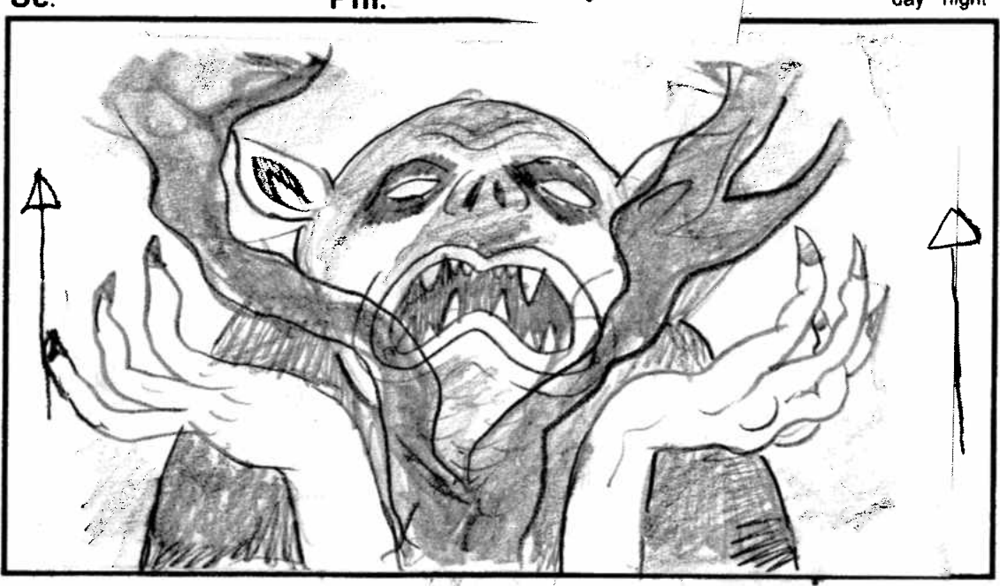

In [20]:
REFERENCE_PANEL_INDEX = 3  # zero-based: panel 4
CHARACTER_PROMPT = "vampire"

reference_source = load_rgb(
    panel_files[REFERENCE_PANEL_INDEX]
)

print(
    "Reference source:",
    panel_files[REFERENCE_PANEL_INDEX],
)

display(reference_source)

Loading weights:   0%|          | 0/665 [00:00<?, ?it/s]

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

/tmp/ipykernel_2581/1246332352.py:86: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return Image.fromarray(mask_array, mode="L")


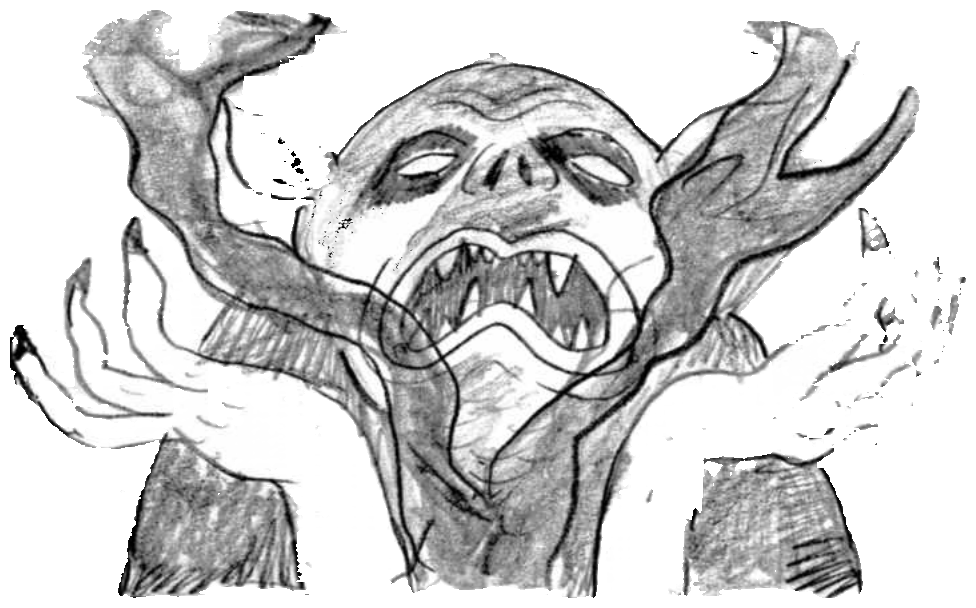

In [21]:
locator = Florence2CharacterLocator()

segmenter = SAM2CharacterSegmenter()

extractor = CharacterReferenceExtractor(
    locator=locator,
    segmenter=segmenter,
    background_strategy=SolidBackgroundStrategy(
        "white"
    ),
    padding=10,
)


character_reference = extractor.extract(
    image=reference_source,
    prompt=CHARACTER_PROMPT,
)

display(character_reference)

save the extracted character reference

In [22]:
REFERENCE_PATH = os.path.join(
    REF_DIR,
    "vampire_ref.png",
)

character_reference.save(
    REFERENCE_PATH
)

print(
    "Saved character reference:",
    REFERENCE_PATH,
)

Saved character reference: /content/drive/MyDrive/cmpe261_project/char_refs/vampire_ref.png


Free up GPU memeory

In [26]:
del extractor
del locator
del segmenter

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

print("Character cropper models unloaded.")

Character cropper models unloaded.


## 6. Side-by-side preview (storyboard vs. generated)

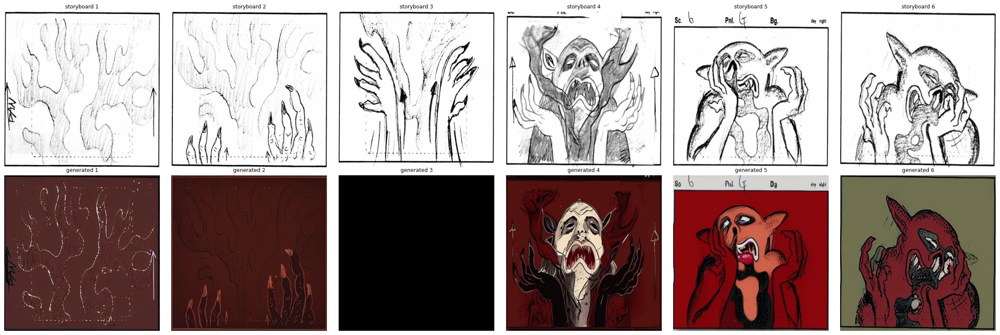

In [27]:
if panel_files:
    originals = [load_rgb(p).resize((CONFIG['resolution'],)*2) for p in panel_files]
    show(originals + frames,
         titles=[f'storyboard {i+1}' for i in range(len(originals))] +
                [f'generated {i+1}' for i in range(len(frames))],
         cols=len(frames))

# ControlNet only vs. ControlNet and IP-Adapter

In [41]:
IP_ADAPTER_CONFIG = {
    "repo": "h94/IP-Adapter",
    "subfolder": "models",
    # "weight_name": "ip-adapter_sd15.bin",
    "weight_name": "ip-adapter-plus_sd15.bin",
    "scale": 0.2,
}

pipe.load_ip_adapter(
    IP_ADAPTER_CONFIG["repo"],
    subfolder=IP_ADAPTER_CONFIG["subfolder"],
    weight_name=IP_ADAPTER_CONFIG["weight_name"],
)

pipe.set_ip_adapter_scale(
    IP_ADAPTER_CONFIG["scale"]
)

print("encoder_hid_proj:", pipe.unet.encoder_hid_proj)
print("image_encoder:", pipe.image_encoder)

assert pipe.unet.encoder_hid_proj is not None, \
    "IP-Adapter projection layers were not loaded."

assert pipe.image_encoder is not None, \
    "IP-Adapter image encoder was not loaded."

print("IP-Adapter successfully attached")

models/ip-adapter-plus_sd15.bin: reconstructing file:   0%|          |  0.00B /  158MB            

models/ip-adapter-plus_sd15.bin: downloading bytes:           |  0.00B            

There are modules in UNet2DConditionModel that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


encoder_hid_proj: MultiIPAdapterImageProjection(
  (image_projection_layers): ModuleList(
    (0): IPAdapterPlusImageProjection(
      (proj_in): Linear(in_features=1280, out_features=768, bias=True)
      (proj_out): Linear(in_features=768, out_features=768, bias=True)
      (norm_out): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
      (layers): ModuleList(
        (0-3): 4 x IPAdapterPlusImageProjectionBlock(
          (ln0): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
          (ln1): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
          (attn): Attention(
            (to_q): Linear(in_features=768, out_features=768, bias=False)
            (to_k): Linear(in_features=768, out_features=768, bias=False)
            (to_v): Linear(in_features=768, out_features=768, bias=False)
            (to_out): ModuleList(
              (0): Linear(in_features=768, out_features=768, bias=False)
              (1): Dropout(p=0.0, inplace=False)
            )
          )


Reference size: (976, 608)


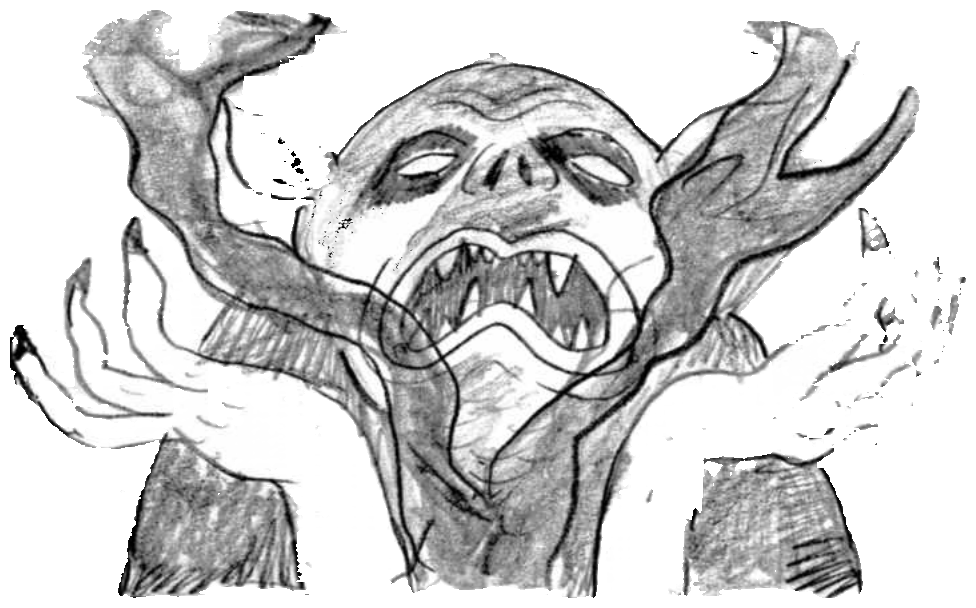

In [42]:
REFERENCE_PATH = os.path.join(
    REF_DIR,
    "vampire_ref.png",
)

def load_character_reference(path):
    return Image.open(path).convert("RGB")

character_reference = load_character_reference(
    REFERENCE_PATH
)

print("Reference size:", character_reference.size)
display(character_reference)

In [43]:
def run_sequence_ip_adapter(
    seq_name,
    panel_files,
    prompts,
    character_reference,
    method="controlnet_ip_adapter",
    cfg=CONFIG,
    ip_cfg=IP_ADAPTER_CONFIG,
):
    """
    Generate a storyboard sequence using ControlNet and IP-Adapter.

    ControlNet conditions generation on storyboard structure, while
    IP-Adapter conditions generation on character appearance.

    The remaining generation settings are kept identical to the
    ControlNet-only baseline for comparison.
    """
    assert len(panel_files) == len(prompts), \
        "need one prompt per panel"

    out_dir = os.path.join(
        OUTPUT_DIR,
        method,
        seq_name,
    )
    os.makedirs(out_dir, exist_ok=True)

    results = []

    for i, (pf, prompt) in enumerate(
        zip(panel_files, prompts),
        1,
    ):
        # Same ControlNet condition used by the baseline.
        cond = make_condition(
            load_rgb(pf),
            cfg["cond_mode"],
            cfg["resolution"],
            cfg["canny_low"],
            cfg["canny_high"],
        )

        # Reset to the same seed used by the baseline so the
        # comparison changes the conditioning method, not the noise.
        gen = torch.Generator("cuda").manual_seed(
            cfg["seed"]
        )

        img = pipe(
            prompt=f"{prompt}, {cfg['prompt_suffix']}",
            negative_prompt=cfg["negative_prompt"],

            # ControlNet structural condition.
            image=cond,

            # IP-Adapter identity/appearance condition.
            ip_adapter_image=character_reference,

            num_inference_steps=cfg["steps"],
            guidance_scale=cfg["guidance_scale"],
            controlnet_conditioning_scale=(
                cfg["controlnet_conditioning_scale"]
            ),
            generator=gen,
        ).images[0]

        img.save(
            os.path.join(
                out_dir,
                f"panel{i:02d}.png",
            )
        )

        cond.save(
            os.path.join(
                out_dir,
                f"panel{i:02d}_cond.png",
            )
        )

        results.append(img)

    # Store enough information to reproduce this run.
    record = {
        "method": method,
        "sequence": seq_name,
        "panel_files": panel_files,
        "prompts": prompts,
        "config": cfg,
        "ip_adapter": {
            "repo": ip_cfg["repo"],
            "subfolder": ip_cfg["subfolder"],
            "weight_name": ip_cfg["weight_name"],
            "scale": ip_cfg["scale"],
            "reference_image": REFERENCE_PATH,
        },
        "timestamp": time.strftime(
            "%Y-%m-%d %H:%M:%S"
        ),
        "torch": torch.__version__,
    }

    with open(
        os.path.join(out_dir, "run_config.json"),
        "w",
    ) as f:
        json.dump(record, f, indent=2)

    return results

In [45]:
if panel_files:
    ip_frames = run_sequence_ip_adapter(
        seq_name=seq_name,
        panel_files=panel_files,
        prompts=prompts,
        character_reference=character_reference,
    )

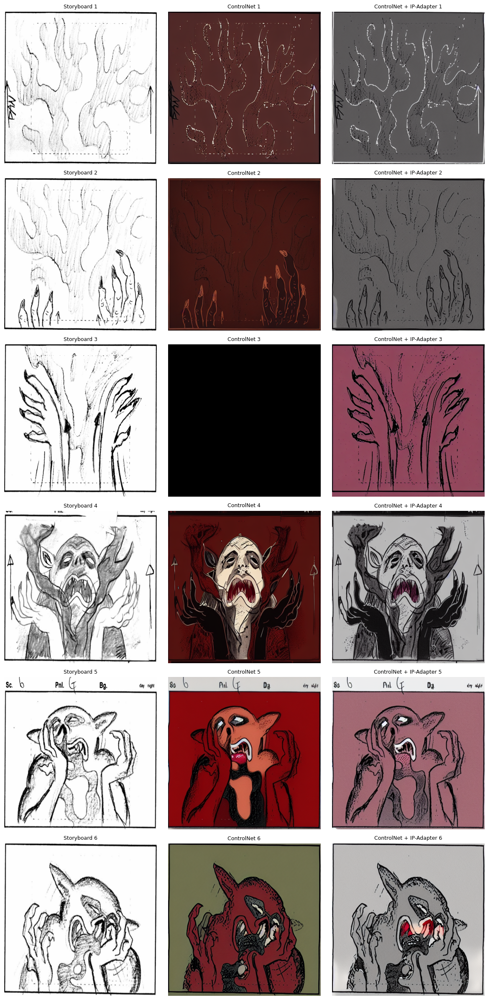

In [46]:
if panel_files:
    originals = [
        load_rgb(p).resize(
            (CONFIG["resolution"],) * 2
        )
        for p in panel_files
    ]

    comparison_images = []
    comparison_titles = []

    for i, (
        original,
        baseline,
        ip_result,
    ) in enumerate(
        zip(originals, frames, ip_frames),
        1,
    ):
        comparison_images.extend([
            original,
            baseline,
            ip_result,
        ])

        comparison_titles.extend([
            f"Storyboard {i}",
            f"ControlNet {i}",
            f"ControlNet + IP-Adapter {i}",
        ])

    show(
        comparison_images,
        titles=comparison_titles,
        cols=3,
        size=4,
    )

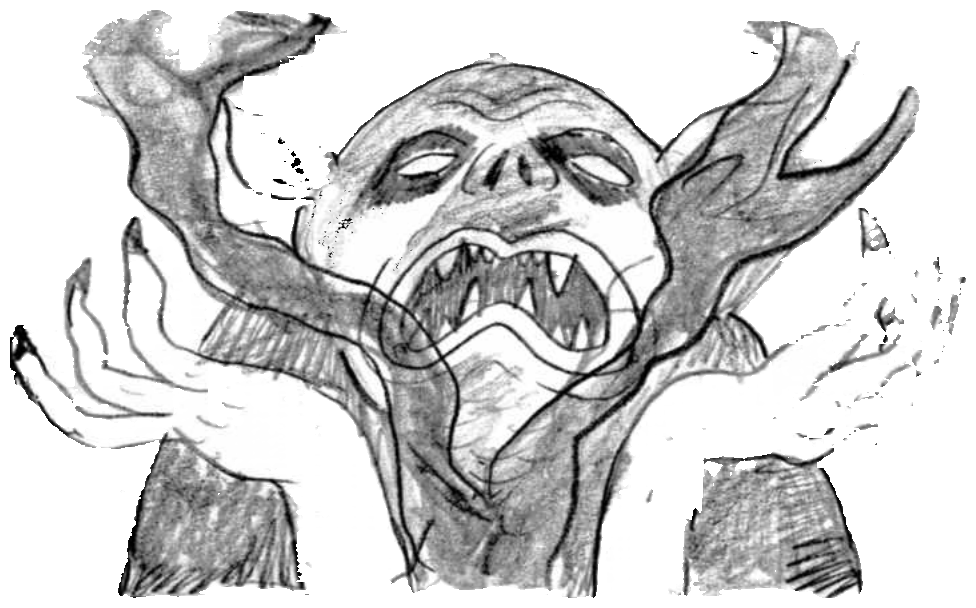

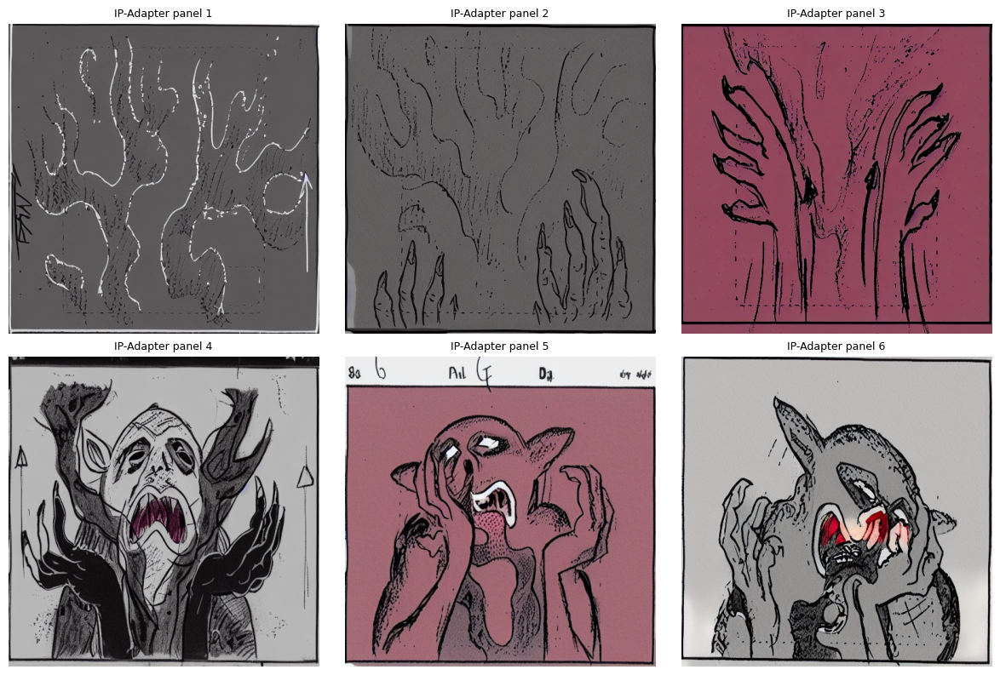

In [47]:
display(character_reference)

show(
    ip_frames,
    titles=[
        f"IP-Adapter panel {i + 1}"
        for i in range(len(ip_frames))
    ],
    cols=3,
    size=4,
)

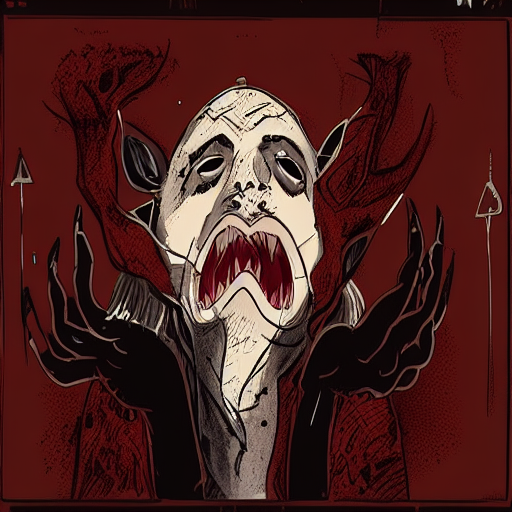

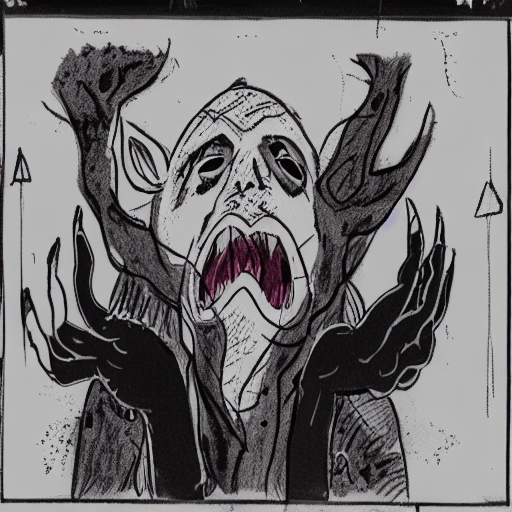

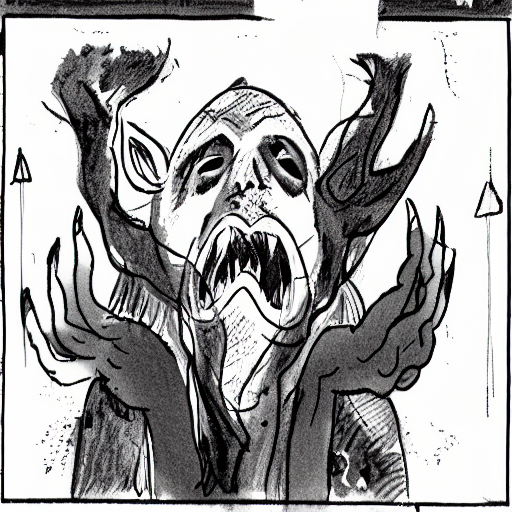

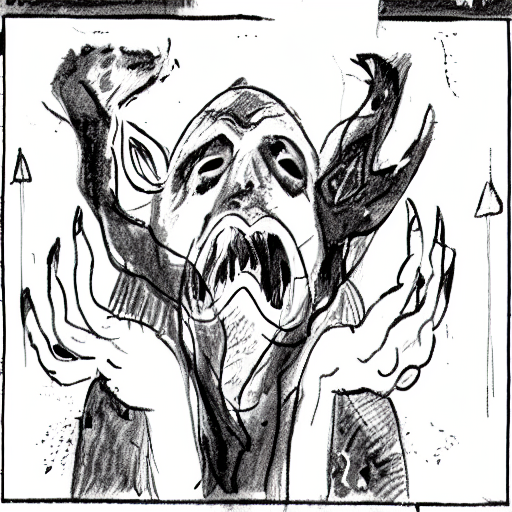

In [48]:
for scale in [0.0, 0.2, 0.4, 0.6]:
    pipe.set_ip_adapter_scale(scale)

    generator = torch.Generator("cuda").manual_seed(
        CONFIG["seed"]
    )

    result = pipe(
        prompt=f"{prompts[3]}, {CONFIG['prompt_suffix']}",
        negative_prompt=CONFIG["negative_prompt"],
        image=make_condition(
            load_rgb(panel_files[3]),
            CONFIG["cond_mode"],
            CONFIG["resolution"],
            CONFIG["canny_low"],
            CONFIG["canny_high"],
        ),
        ip_adapter_image=character_reference,
        num_inference_steps=CONFIG["steps"],
        guidance_scale=CONFIG["guidance_scale"],
        controlnet_conditioning_scale=(
            CONFIG["controlnet_conditioning_scale"]
        ),
        generator=generator,
    ).images[0]

    display(result)

In [50]:
import cv2
import numpy as np
import pandas as pd
from PIL import Image
from scipy.spatial.distance import dice
from sklearn.metrics import jaccard_score
import matplotlib.pyplot as plt
import seaborn as sns


In [51]:
def to_edge_mask(
    image: Image.Image,
    size: int = 512,
    low: int = 100,
    high: int = 200,
    dilation_pixels: int = 1,
) -> np.ndarray:
    """
    Convert an image into a binary Canny edge mask.

    Parameters
    ----------
    image:
        Input PIL image.
    size:
        Output width and height.
    low:
        Lower Canny threshold.
    high:
        Upper Canny threshold.
    dilation_pixels:
        Amount of edge dilation used to tolerate small spatial shifts.
        Use 0 to disable dilation.

    Returns
    -------
    np.ndarray
        Boolean edge mask.
    """
    gray = image.convert("L").resize((size, size))

    edges = cv2.Canny(
        np.array(gray),
        low,
        high,
    )

    if dilation_pixels > 0:
        kernel_size = 2 * dilation_pixels + 1

        kernel = np.ones(
            (kernel_size, kernel_size),
            dtype=np.uint8,
        )

        edges = cv2.dilate(
            edges,
            kernel,
            iterations=1,
        )

    return edges > 0

In [52]:
def compare_edge_masks(
    mask_a: np.ndarray,
    mask_b: np.ndarray,
) -> dict[str, float]:
    """
    Compare two binary masks using Dice similarity and Jaccard/IoU.
    """
    a = mask_a.astype(bool).ravel()
    b = mask_b.astype(bool).ravel()

    # scipy.spatial.distance.dice returns distance,
    # so convert it to similarity.
    dice_similarity = 1.0 - dice(a, b)

    jaccard = jaccard_score(
        a,
        b,
        zero_division=1,
    )

    return {
        "dice": float(dice_similarity),
        "jaccard": float(jaccard),
    }

In [53]:
def compare_structure(
    storyboard: Image.Image,
    generated: Image.Image,
    cfg=CONFIG,
    dilation_pixels: int = 1,
) -> dict[str, float]:
    """
    Compare storyboard structure against a generated image.

    Both images are converted to Canny edge masks before scoring.
    """
    storyboard_edges = to_edge_mask(
        storyboard,
        size=cfg["resolution"],
        low=cfg["canny_low"],
        high=cfg["canny_high"],
        dilation_pixels=dilation_pixels,
    )

    generated_edges = to_edge_mask(
        generated,
        size=cfg["resolution"],
        low=cfg["canny_low"],
        high=cfg["canny_high"],
        dilation_pixels=dilation_pixels,
    )

    return compare_edge_masks(
        storyboard_edges,
        generated_edges,
    )

In [54]:
results = []

for i, (
    panel_path,
    controlnet_image,
    ip_adapter_image,
) in enumerate(
    zip(
        panel_files,
        frames,
        ip_frames,
    ),
    1,
):
    storyboard = load_rgb(panel_path)

    controlnet_scores = compare_structure(
        storyboard,
        controlnet_image,
        dilation_pixels=1,
    )

    ip_adapter_scores = compare_structure(
        storyboard,
        ip_adapter_image,
        dilation_pixels=1,
    )

    results.append({
        "panel": i,

        "controlnet_dice":
            controlnet_scores["dice"],

        "controlnet_jaccard":
            controlnet_scores["jaccard"],

        "ip_adapter_dice":
            ip_adapter_scores["dice"],

        "ip_adapter_jaccard":
            ip_adapter_scores["jaccard"],
    })


results_df = pd.DataFrame(results)

results_df

,panel,controlnet_dice,controlnet_jaccard,ip_adapter_dice,ip_adapter_jaccard
0,1,0.728303,0.572702,0.819503,0.694201
1,2,0.564001,0.392758,0.852212,0.742482
2,3,0.000000,0.000000,0.863178,0.759291
3,4,0.617875,0.447047,0.888823,0.799893
4,5,0.738875,0.585886,0.901173,0.820123
5,6,0.885424,0.794404,0.901420,0.820533


In [55]:
summary_df = pd.DataFrame({
    "method": [
        "ControlNet",
        "ControlNet + IP-Adapter",
    ],

    "mean_dice": [
        results_df["controlnet_dice"].mean(),
        results_df["ip_adapter_dice"].mean(),
    ],

    "mean_jaccard": [
        results_df["controlnet_jaccard"].mean(),
        results_df["ip_adapter_jaccard"].mean(),
    ],
})

summary_df

,method,mean_dice,mean_jaccard
0,ControlNet,0.589080,0.465466
1,ControlNet + IP-Adapter,0.871052,0.772754


In [56]:
print(summary_df.to_string(index=False))

                 method  mean_dice  mean_jaccard
             ControlNet   0.589080      0.465466
ControlNet + IP-Adapter   0.871052      0.772754


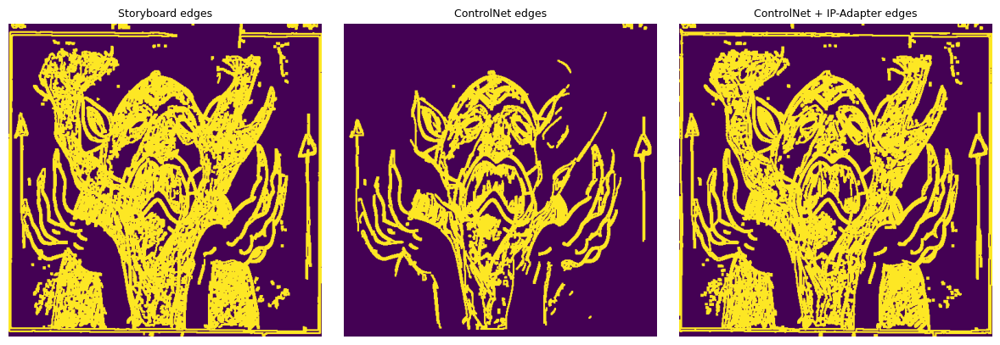

In [57]:
panel_index = 3

storyboard = load_rgb(
    panel_files[panel_index]
)

storyboard_edges = to_edge_mask(
    storyboard,
    size=CONFIG["resolution"],
    low=CONFIG["canny_low"],
    high=CONFIG["canny_high"],
    dilation_pixels=1,
)

controlnet_edges = to_edge_mask(
    frames[panel_index],
    size=CONFIG["resolution"],
    low=CONFIG["canny_low"],
    high=CONFIG["canny_high"],
    dilation_pixels=1,
)

ip_adapter_edges = to_edge_mask(
    ip_frames[panel_index],
    size=CONFIG["resolution"],
    low=CONFIG["canny_low"],
    high=CONFIG["canny_high"],
    dilation_pixels=1,
)

show(
    [
        Image.fromarray(
            storyboard_edges.astype(np.uint8) * 255
        ),
        Image.fromarray(
            controlnet_edges.astype(np.uint8) * 255
        ),
        Image.fromarray(
            ip_adapter_edges.astype(np.uint8) * 255
        ),
    ],
    titles=[
        "Storyboard edges",
        "ControlNet edges",
        "ControlNet + IP-Adapter edges",
    ],
    cols=3,
    size=4,
)

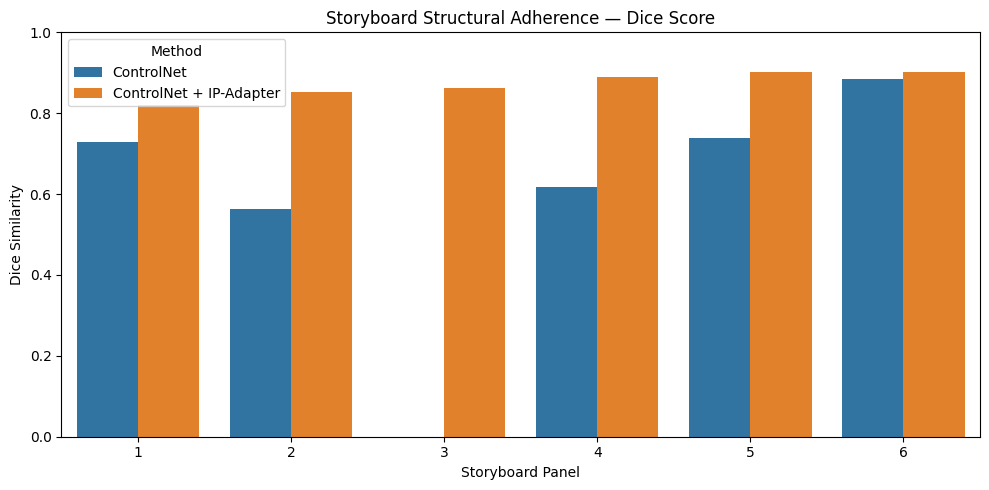

In [58]:

dice_plot = results_df.melt(
    id_vars="panel",
    value_vars=[
        "controlnet_dice",
        "ip_adapter_dice",
    ],
    var_name="method",
    value_name="dice",
)

dice_plot["method"] = dice_plot["method"].replace({
    "controlnet_dice": "ControlNet",
    "ip_adapter_dice": "ControlNet + IP-Adapter",
})

plt.figure(figsize=(10, 5))

sns.barplot(
    data=dice_plot,
    x="panel",
    y="dice",
    hue="method",
)

plt.title("Storyboard Structural Adherence — Dice Score")
plt.xlabel("Storyboard Panel")
plt.ylabel("Dice Similarity")
plt.ylim(0, 1)
plt.legend(title="Method")
plt.tight_layout()
plt.show()

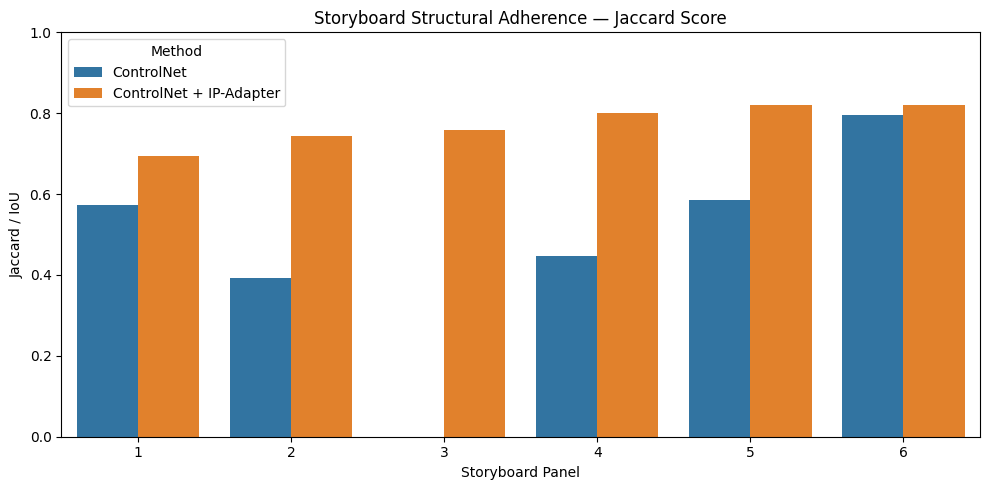

In [59]:
jaccard_plot = results_df.melt(
    id_vars="panel",
    value_vars=[
        "controlnet_jaccard",
        "ip_adapter_jaccard",
    ],
    var_name="method",
    value_name="jaccard",
)

jaccard_plot["method"] = jaccard_plot["method"].replace({
    "controlnet_jaccard": "ControlNet",
    "ip_adapter_jaccard": "ControlNet + IP-Adapter",
})

plt.figure(figsize=(10, 5))

sns.barplot(
    data=jaccard_plot,
    x="panel",
    y="jaccard",
    hue="method",
)

plt.title("Storyboard Structural Adherence — Jaccard Score")
plt.xlabel("Storyboard Panel")
plt.ylabel("Jaccard / IoU")
plt.ylim(0, 1)
plt.legend(title="Method")
plt.tight_layout()
plt.show()

## 7. Character reference crops
For IP-Adapter later, save a clean crop of each main character (from the storyboards or model sheets if available). Use the grid overlay to read pixel coordinates.

In [39]:
def grid_view(img, figsize=(12, 12)):
    plt.figure(figsize=figsize); plt.imshow(img); plt.grid(True, alpha=0.4); plt.show()

def save_ref(img, box, name):
    crop = img.crop(box)
    path = os.path.join(REF_DIR, f'{name}.png')
    crop.save(path); return crop

# grid_view(page)
# ref = save_ref(page, (120, 80, 420, 480), 'fox_front')   # EDIT box
# ref

## 8. Hooks for the other methods
Reuse `run_sequence`'s structure (same panels, prompts, seed, config, saved `run_config.json`) for each method so outputs are directly comparable:

- **IP-Adapter:** `pipe.load_ip_adapter(...)`, then pass a reference crop from `REF_DIR` as `ip_adapter_image`. Supported in `diffusers`.
- **StoryDiffusion:** official repo (`HVision-NKU/StoryDiffusion`), Consistent Self-Attention; generates panels as a batch.
- **ConsiStory:** official repo (`NVlabs/consistory`), training-free shared attention across a batch.
- **The Chosen One:** iterative identity clustering; much heavier compute, so decide early whether it's feasible on Colab.

Check each repo's README for its memory requirements and whether it can take a ControlNet layout condition, since this affects how fair the comparison is.